# Сравнение методов Feature Engineering

## 1. Введение

Проверяем, какие признаки дают лучший баланс качества, времени расчета и понятности
в одной и той же LightGBM-модели. Сравниваем признаки без истории, ручные временные
агрегаты и автоматическую генерацию с отбором на validation.

Два независимых эксперимента: KION — доля просмотра ≥50% среди наблюдаемых
пользователь–фильм агрегатов; Yambda — like против dislike среди явных реакций.
Это binary classification. Основная метрика — LogLoss, дополнительные — ROC-AUC и
average precision. Качество выдачи по всему каталогу эти задачи не измеряют.

Гипотеза: расширение набора агрегатов может улучшить прогноз, а последующий отбор
позволяет убрать лишние признаки и сократить стоимость расчета. Проверяем это на
одинаковых данных, разбиениях и параметрах модели.

Первая ячейка проверяет зависимости и при необходимости выполняет `%pip install`
в окружении текущего kernel. По умолчанию выбран полный эксперимент; `demo` оставлен
для быстрой проверки на 100k событий. Сохраненные outputs относятся к `full`.


In [1]:
from importlib import metadata

# Устанавливаем только отсутствующие пакеты или версии, отличающиеся от проверенных.
# Используем %pip через API IPython: установка попадет в окружение текущего kernel.
REQUIRED_PACKAGES = ['numpy==2.3.2', 'polars==1.43.2', 'pandas==2.3.1', 'lightgbm==4.6.0', 'scikit-learn==1.7.2', 'scipy==1.16.3', 'matplotlib==3.10.9', 'psutil==7.0.0', 'nbformat==5.10.4', 'nbclient==0.10.2', 'ipykernel==6.30.0']
install = []
for requirement in REQUIRED_PACKAGES:
    package, expected = requirement.split("==")
    try:
        actual = metadata.version(package)
    except metadata.PackageNotFoundError:
        actual = None
    if actual != expected:
        install.append(requirement)
if install:
    get_ipython().run_line_magic("pip", "install --disable-pip-version-check " + " ".join(install))
assert all(metadata.version(name.split("==")[0]) == name.split("==")[1] for name in REQUIRED_PACKAGES)
print("Зависимости установлены и совпадают с requirements.txt")

Зависимости установлены и совпадают с requirements.txt


In [2]:
import os
os.environ.setdefault("POLARS_MAX_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/fe-comparison-mpl")

import gc
import io
import json
import re
import hashlib
import urllib.request
import zipfile
from collections import defaultdict
from dataclasses import asdict, dataclass
from datetime import datetime, timedelta
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import polars as pl
import lightgbm as lgb
import matplotlib.pyplot as plt
import psutil
from sklearn.metrics import log_loss, roc_auc_score, average_precision_score
from IPython.display import display

MODE = os.environ.get("FE_MODE", "full")  # demo: 100k rows; full: all rows
DATASETS = os.environ.get("FE_DATASETS", "kion,yambda").split(",")
SEED = 42
assert MODE in {"demo", "full"} and set(DATASETS) <= {"kion", "yambda"}
RUN = Path(".runs") / (MODE + "_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
RUN.mkdir(parents=True, exist_ok=False)
CONFIG = {"threads": 4, "max_estimators": 80 if MODE == "demo" else 600,
          "early_stopping_rounds": 10 if MODE == "demo" else 40}
WINDOWS = [1, 7, 30, None] if MODE == "demo" else [1, 3, 7, 14, 21, 30, 60, 90, 180, None]
BUDGETS = [16, 32] if MODE == "demo" else [32, 64, 96, 128]
PRUNING = {"max_missing_fraction": .999, "near_constant_fraction": .9999,
           "correlation_threshold": .9999}
THRESHOLD = .0001
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print("Mode:", MODE, "datasets:", DATASETS, "outputs:", RUN)

Mode: full datasets: ['kion', 'yambda'] outputs: .runs/full_20261025_180607


`demo` проверяет весь путь, включая обучение и test, на первых 100 тысячах событий.
Его цифры нельзя выдавать за полный эксперимент. По умолчанию используется `full`;
режим можно изменить через `MODE` или переменную окружения `FE_MODE`.
Новый каталог создается при каждом Run All; старые результаты не перезаписываются.

Параметры LightGBM ниже заранее зафиксированы после настройки на manual features.
Они одинаковы для всех методов внутри dataset. В этом notebook нового HPO нет:
сравнение посвящено признакам, а не поиску лучшей конфигурации модели.


In [3]:
SOURCES = {'kion': {'dataset': 'kion', 'revision': 'f69775be31fa5779907cf0a92ddedb70037fb5ae', 'files': [{'name': 'items.csv', 'size': 31836561, 'url': 'https://raw.githubusercontent.com/irsafilo/KION_DATASET/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original/items.csv', 'sha256': '027c3a0027b4fe4a8db9d5fa626ab40bab507c96aac81d462db0771eb2cb4a8e'}, {'name': 'users.csv', 'size': 29945389, 'url': 'https://raw.githubusercontent.com/irsafilo/KION_DATASET/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original/users.csv', 'sha256': '37b2945240628a3f215e1fb5f79b4cff386d8988b21fa61e5b135aef4541182c'}, {'name': 'interactions.csv.zip', 'size': 18651415, 'url': 'https://raw.githubusercontent.com/irsafilo/KION_DATASET/f69775be31fa5779907cf0a92ddedb70037fb5ae/interactions.csv.zip', 'sha256': '2f57f04bc1788a3d6aa652c6478a06f597af0f34f837ba448a2a28534eae3039'}]}, 'yambda': {'dataset': 'yambda', 'revision': 'dd6f3a19eef5866e346c3270e098baa641a44948', 'scale': '50m', 'files': [{'name': 'album_item_mapping.parquet', 'size': 54528894, 'sha256': '559b6576063d96280414574b32292eee7b47ee0b9f2952cb3ae670a5d19125e4', 'url': 'https://huggingface.co/datasets/yandex/yambda/resolve/dd6f3a19eef5866e346c3270e098baa641a44948/album_item_mapping.parquet?download=true'}, {'name': 'artist_item_mapping.parquet', 'size': 38274621, 'sha256': 'cf1110aa2413ed70008ec9232d395660b2181ffda731002fb74da54e87b6f25d', 'url': 'https://huggingface.co/datasets/yandex/yambda/resolve/dd6f3a19eef5866e346c3270e098baa641a44948/artist_item_mapping.parquet?download=true'}, {'name': 'dislikes.parquet', 'size': 990007, 'sha256': '64f240a6d62b8acdfa6efae660a54d10ebc64f9f2f0aeeef8e6bb0dbe7dc2802', 'url': 'https://huggingface.co/datasets/yandex/yambda/resolve/dd6f3a19eef5866e346c3270e098baa641a44948/flat/50m/dislikes.parquet?download=true'}, {'name': 'likes.parquet', 'size': 7180817, 'sha256': '694087077dbacfcc1d22a5ca85cc6bd8ab182361933406e60500624c6a422bc4', 'url': 'https://huggingface.co/datasets/yandex/yambda/resolve/dd6f3a19eef5866e346c3270e098baa641a44948/flat/50m/likes.parquet?download=true'}]}}

COMMON_PARAMS = {'kion': {'num_leaves': 15, 'min_child_samples': 58, 'learning_rate': 0.05684643805756514, 'colsample_bytree': 0.7788256170798835, 'reg_lambda': 1.1429019414069517, 'reg_alpha': 0.0011963231821493767}, 'yambda': {'num_leaves': 31, 'min_child_samples': 267, 'learning_rate': 0.07282676635774393, 'colsample_bytree': 0.6759156281069316, 'reg_lambda': 0.7726148927746461, 'reg_alpha': 0.002528661927134373}}


## 2. Данные и EDA

KION содержит один агрегат на user–item с точностью даты до дня. Строки без watched_pct
исключены, текущие watched_pct/total_dur не входят в модель. Историческая доля просмотра
допустима только из предыдущих дней. В Yambda взяты все likes/dislikes из flat/50m,
а не все 50M действий. Время уже измерено в относительных секундах, округленных вниз
до 5s: дополнительно умножать его на пять нельзя. Календарные признаки для него отключены.

Многозначные metadata упрощены первый жанр/режиссер
KION и минимальный album/artist ID Yambda. Это предотвращает row explosion, но теряет
часть информации. Metadata считаются заранее известными; их исторические версии отсутствуют.

In [4]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def locate_raw_data():
    if os.environ.get("FE_RAW_DIR"):
        return Path(os.environ["FE_RAW_DIR"])
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data/raw/kion").exists():
            return folder / "data/raw"
    return Path(".data/raw")


RAW = locate_raw_data()
for dataset in DATASETS:
    for entry in SOURCES[dataset]["files"]:
        path = RAW / dataset / entry["name"]
        if not path.exists():
            path.parent.mkdir(parents=True, exist_ok=True)
            partial = path.with_suffix(path.suffix + ".part")
            print("Downloading", entry["name"], flush=True)
            with urllib.request.urlopen(entry["url"], timeout=120) as response, partial.open("wb") as stream:
                for block in iter(lambda: response.read(1024 * 1024), b""):
                    stream.write(block)
            assert sha256(partial) == entry["sha256"], "Downloaded source checksum differs"
            partial.replace(path)
        assert path.stat().st_size == entry["size"] and sha256(path) == entry["sha256"], path
print("Pinned raw files verified:", RAW)

Pinned raw files verified: /Users/abdr/Documents/ChatGPT/Yandex/temporal_feature_search/data/raw


In [5]:
def validate_data(df):
    required = {"user_id", "item_id", "timestamp", "label", "event", "row_id"}
    if not required <= set(df.columns):
        raise ValueError(f"Missing columns: {required - set(df.columns)}")
    if df.select(pl.any_horizontal(pl.col(c).is_null() for c in required).any()).item():
        raise ValueError("Required identifiers, times, events and targets cannot be null")
    if df["row_id"].n_unique() != df.height:
        raise ValueError("row_id must be unique")
    if not df["timestamp"].is_sorted():
        raise ValueError("Interactions must be sorted by timestamp")

In [6]:
def positive_event(events):
    for event in ["positive", "like", "watch_high"]:
        if event in events:
            return event
    return sorted(events)[-1]


def finish_interactions(df):
    df = df.sort(["timestamp", "user_id", "item_id", "event"]).with_row_index("row_id")
    validate_data(df)
    if set(df["label"].unique().to_list()) != {0, 1}:
        raise ValueError("Both binary labels are required")
    return df


def kion_interactions(interactions, users, items, user_modulus=1):
    """Predict reported aggregate watch percentage; same-day records are atomic."""
    required = {"user_id", "item_id", "last_watch_dt", "watched_pct"}
    if not required <= set(interactions.columns):
        raise ValueError(f"KION columns missing: {required - set(interactions.columns)}")
    if user_modulus < 1:
        raise ValueError("user_modulus must be >= 1")
    df = interactions.filter(pl.col("user_id") % user_modulus == 0)
    df = df.with_columns(pl.col("watched_pct").cast(pl.Float64, strict=False))
    df = df.filter(pl.col("watched_pct").is_not_null() & (pl.col("watched_pct") >= 0))
    users = users.select("user_id", "age", "income", "sex", "kids_flg").rename({"sex": "gender"})
    items = items.select("item_id", "content_type", "release_year", "genres", "countries",
                         "for_kids", "age_rating", "directors").with_columns(
        pl.col("genres").str.split(",").list.first().str.strip_chars().alias("category_id"),
        pl.col("directors").str.split(",").list.first().str.strip_chars().alias("author"),
    ).drop("directors")
    df = df.join(users, on="user_id", how="left", validate="m:1").join(
        items, on="item_id", how="left", validate="m:1")
    df = df.with_columns(
        pl.col("last_watch_dt").cast(pl.String).str.to_date().cast(pl.Datetime("us")).alias("timestamp"),
        (pl.col("watched_pct") >= 50).cast(pl.Int8).alias("label"),
        pl.when(pl.col("watched_pct") >= 50).then(pl.lit("watch_high")).otherwise(
            pl.lit("watch_low")).alias("event"),
        pl.col("watched_pct").alias("history_value"),
        pl.lit(False).alias("time_is_relative"),
    ).drop("last_watch_dt", "watched_pct")
    if "total_dur" in df.columns:
        df = df.drop("total_dur")  # Длительность текущего просмотра стала бы подсказкой о target.
    df = df.with_columns([pl.col(c).fill_null("__unknown__") for c in
                          ["category_id", "author", "gender", "genres", "countries", "content_type", "income", "age"]])
    return finish_interactions(df)


def load_kion(raw_dir="data/raw", user_modulus=1):
    folder = Path(raw_dir) / "kion"
    with zipfile.ZipFile(folder / "interactions.csv.zip") as archive:
        members = [name for name in archive.namelist() if Path(name).name == "interactions.csv"]
        if len(members) != 1:
            raise ValueError("Expected one interactions.csv in official KION archive")
        interactions = pl.read_csv(io.BytesIO(archive.read(members[0])), infer_schema_length=10000)
    return kion_interactions(interactions, pl.read_csv(folder / "users.csv", infer_schema_length=10000),
                             pl.read_csv(folder / "items.csv", infer_schema_length=10000), user_modulus)


def yambda_interactions(likes, dislikes, artists, albums):
    # В статье T' = floor((T-T0)/5)*5: это уже секунды, округленные до 5s.
    # Повторное умножение на пять растянуло бы все временные окна.
    df = pl.concat([likes.with_columns(pl.lit("like").alias("event"), pl.lit(1, pl.Int8).alias("label")),
                    dislikes.with_columns(pl.lit("dislike").alias("event"), pl.lit(0, pl.Int8).alias("label"))])
    df = df.rename({"uid": "user_id", "timestamp": "relative_seconds"})
    if df.filter(pl.col("relative_seconds") % 5 != 0).height:
        raise ValueError("Yambda timestamps must be multiples of 5 seconds")
    if not df["is_organic"].is_in([0, 1]).all():
        raise ValueError("Invalid is_organic flag")
    # У item может быть несколько артистов и альбомов. Для этого эксперимента берем
    # минимальный ID, чтобы join не размножил события; часть информации при этом теряется.
    artists = artists.group_by("item_id").agg(pl.col("artist_id").min().alias("author"))
    albums = albums.group_by("item_id").agg(pl.col("album_id").min().alias("category_id"))
    df = df.join(artists, on="item_id", how="left", validate="m:1").join(
        albums, on="item_id", how="left", validate="m:1").with_columns(
        pl.from_epoch(pl.col("relative_seconds").cast(pl.Int64), time_unit="s").alias("timestamp"),
        pl.col("author").cast(pl.String).fill_null("__unknown__"),
        pl.col("category_id").cast(pl.String).fill_null("__unknown__"),
        pl.lit(True).alias("time_is_relative"),
    )
    return finish_interactions(df)


def load_yambda(raw_dir="data/raw"):
    folder = Path(raw_dir) / "yambda"
    return yambda_interactions(*[pl.read_parquet(folder / name) for name in
                                 ["likes.parquet", "dislikes.parquet", "artist_item_mapping.parquet", "album_item_mapping.parquet"]])

In [7]:
@dataclass(frozen=True)
class TemporalSplit:
    train_end: int
    search_end: int
    validation_end: int
    n_rows: int

    @property
    def train(self):
        return np.arange(self.train_end)

    @property
    def search(self):
        return np.arange(self.train_end, self.search_end)

    @property
    def audit(self):
        return np.arange(self.search_end, self.validation_end)

    @property
    def test(self):
        return np.arange(self.validation_end, self.n_rows)


def temporal_split(df, fractions=(0.70, 0.775, 0.85)):
    if not df.height or not df["timestamp"].is_sorted() or df["timestamp"].null_count():
        raise ValueError("Temporal split requires nonempty, sorted, non-null timestamps")
    times = df["timestamp"].to_numpy()
    if not 0 < fractions[0] < fractions[1] < fractions[2] < 1:
        raise ValueError("Expected train < search validation < audit validation < test")
    # Номинальная граница может попасть внутрь дня или 5s bin. Сдвигаем ее
    # к первому событию этого timestamp, чтобы одинаковое время не разделилось между частями.
    bounds = [int(np.searchsorted(times, times[int(len(times) * f)], side="left"))
              for f in fractions]
    if not 0 < bounds[0] < bounds[1] < bounds[2] < len(times):
        raise ValueError("Too few distinct timestamps for temporal split")
    for bound in bounds:
        assert times[bound - 1] < times[bound], "Equal timestamps crossed a split"
    return TemporalSplit(*bounds, len(times))

kion schema: {'row_id': 'UInt32', 'user_id': 'Int64', 'item_id': 'Int64', 'age': 'String', 'income': 'String', 'gender': 'String', 'kids_flg': 'Int64', 'content_type': 'String', 'release_year': 'Float64', 'genres': 'String', 'countries': 'String', 'for_kids': 'Float64', 'age_rating': 'Float64', 'category_id': 'String', 'author': 'String', 'timestamp': "Datetime(time_unit='us', time_zone=None)", 'label': 'Int8', 'event': 'String', 'history_value': 'Float64', 'time_is_relative': 'Boolean'}


,column,missing
0,kids_flg,305733
1,release_year,95
2,for_kids,1559028
3,age_rating,3


yambda schema: {'row_id': 'UInt32', 'user_id': 'UInt32', 'relative_seconds': 'UInt32', 'item_id': 'UInt32', 'is_organic': 'UInt8', 'event': 'String', 'label': 'Int8', 'author': 'String', 'category_id': 'String', 'timestamp': "Datetime(time_unit='us', time_zone=None)", 'time_is_relative': 'Boolean'}


,column,missing


,dataset,rows,users,items,start,end,train_positive_rate,duplicate_events
0,kion,1594519,567555,12639,2021-03-13 00:00:00,2021-08-22 00:00:00,0.472883,0
1,yambda,989232,8544,194996,1970-01-01 00:01:15,1970-10-28 22:12:50,0.885442,6654


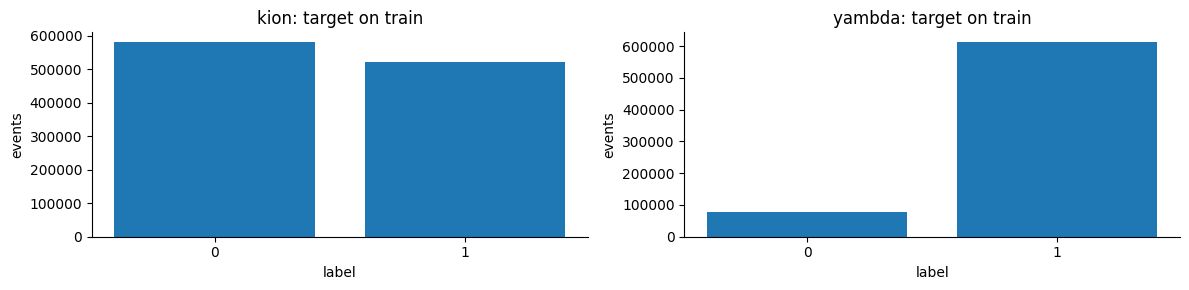

In [8]:
frames, splits, eda = {}, {}, []
for dataset in DATASETS:
    frame = load_kion(RAW) if dataset == "kion" else load_yambda(RAW)
    if MODE == "demo":
        frame = frame.head(100000)
    frames[dataset] = frame
    splits[dataset] = temporal_split(frame)
    train = frame.head(splits[dataset].train_end)
    eda.append({"dataset": dataset, "rows": frame.height, "users": frame["user_id"].n_unique(),
                "items": frame["item_id"].n_unique(), "start": str(frame["timestamp"].min()),
                "end": str(frame["timestamp"].max()), "train_positive_rate": train["label"].mean(),
                "duplicate_events": frame.height-frame.unique(["user_id", "item_id", "timestamp", "label"]).height})
    print(dataset, "schema:", {k: str(v) for k, v in frame.schema.items()})
    missing = frame.null_count().unpivot(variable_name="column", value_name="missing").filter(pl.col("missing") > 0)
    display(pd.DataFrame(missing.to_dicts(), columns=["column", "missing"]))
display(pd.DataFrame(eda))
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6*len(DATASETS), 3), squeeze=False)
for ax, dataset in zip(axes[0], DATASETS):
    train = frames[dataset].head(splits[dataset].train_end)
    counts = train.group_by("label").len().sort("label")
    ax.bar(counts["label"].cast(pl.String), counts["len"])
    ax.set(title=dataset + ": target on train", xlabel="label", ylabel="events")
plt.tight_layout()
plt.show()

## 3. Подготовка и защита от leakage

Global temporal split: около 70% train, 7.5% search, 7.5% контрольная validation, 15% test.
Одинаковые timestamps не разделяются. Encoder и pruning fit-ятся только на train;
search выбирает размер набора и число деревьев. Контрольная validation не участвует в выборе.
После lock модели fit-ятся на первых 85% с фиксированным числом деревьев, затем оцениваются на test.

История для T — `[T−W, T)`, то есть текущее событие и весь его timestamp исключены.
Это online replay: более ранние исходы внутри holdout доступны следующим событиям.
Для production нужны настоящие label availability timestamps. У KION мы предполагаем
доступность агрегата после last_watch_day; файл не позволяет доказать это допущение.

In [9]:
partition_rows = []
for dataset, frame in frames.items():
    split = splits[dataset]
    previous = None
    for name, ids in [("train", split.train), ("search", split.search), ("audit", split.audit), ("test", split.test)]:
        part = frame[ids]
        assert previous is None or previous < part["timestamp"].min()
        previous = part["timestamp"].max()
        partition_rows.append({"dataset": dataset, "part": name, "rows": part.height,
                               "start": str(part["timestamp"].min()), "end": str(previous)})
display(pd.DataFrame(partition_rows))

,dataset,part,rows,start,end
0,kion,train,1103170,2021-03-13 00:00:00,2021-07-23 00:00:00
1,kion,search,121125,2021-07-24 00:00:00,2021-07-31 00:00:00
2,kion,audit,129777,2021-08-01 00:00:00,2021-08-08 00:00:00
3,kion,test,240447,2021-08-09 00:00:00,2021-08-22 00:00:00
4,yambda,train,692462,1970-01-01 00:01:15,1970-08-25 05:19:25
5,yambda,search,74192,1970-08-25 05:19:45,1970-09-11 08:40:55
6,yambda,audit,74193,1970-09-11 08:41:20,1970-09-28 12:30:25
7,yambda,test,148385,1970-09-28 12:30:55,1970-10-28 22:12:50


## 4. Baseline и модель

Raw baseline получает user/item IDs, доступные metadata и известные календарные поля
(только KION). Словари категорий строятся на train; неизвестные значения получают −1,
который LightGBM обрабатывает как missing category. Event, label, текущий outcome в
base matrix не входят. Все методы используют один encoder, seed=42, общие параметры,
одинаковый early stopping и одинаковые строки обучения.

In [10]:
BASE_CATEGORICAL = ["user_id", "item_id", "gender", "age", "occupation", "category_id", "genres",
                    "author", "income", "kids_flg", "content_type", "countries", "for_kids", "age_rating", "is_organic"]


def fit_encoder(df):
    # Словарь строим на обучающем префиксе. Новые ID не должны заранее попасть в него.
    columns = [c for c in BASE_CATEGORICAL if c in df.columns]
    return {c: {str(value): i for i, value in enumerate(sorted(df[c].drop_nulls().cast(pl.String).unique().to_list()))}
            for c in columns}


def base_matrix(df, encoder):
    arrays, names = [], []
    for c, mapping in encoder.items():
        arrays.append(df[c].cast(pl.String).replace_strict(mapping, default=-1, return_dtype=pl.Int32).to_numpy())
        names.append(c)
    categorical = list(range(len(names)))
    if "release_year" in df.columns:
        arrays.append(df["release_year"].cast(pl.Float32).to_numpy())
        names.append("release_year")
    # Час и день недели известны в момент запроса. У Yambda время относительное,
    # поэтому календарные признаки из искусственной даты 1970 года не добавляем.
    if "time_is_relative" not in df.columns or not df["time_is_relative"].any():
        arrays.extend([df["timestamp"].dt.hour().to_numpy(), df["timestamp"].dt.weekday().to_numpy()])
        names.extend(["hour", "weekday"])
    return np.column_stack(arrays).astype(np.float32), names, categorical


def matrix_from_features(base, features, names):
    if not names:
        return base
    if len(base) != features.height:
        raise ValueError("Base/temporal feature rows differ")
    # Заполняем одну float32-матрицу по колонкам, чтобы не держать в памяти
    # еще одну полную копию широкого набора признаков.
    matrix = np.empty((len(base), base.shape[1] + len(names)), dtype=np.float32)
    matrix[:, :base.shape[1]] = base
    for column, name in enumerate(names, start=base.shape[1]):
        matrix[:, column] = features[name].to_numpy()
    return matrix


def take_rows(matrix, indices):
    if len(indices) and np.all(np.diff(indices) == 1):
        return matrix[int(indices[0]):int(indices[-1]) + 1]
    return matrix[indices]


def fit_model(x, y, train, valid, feature_names, categorical, params, config, seed=42,
              fixed_iterations=None):
    tick = perf_counter()
    options = {"objective": "binary", "n_estimators": fixed_iterations or config["max_estimators"],
               "learning_rate": 0.05, "num_leaves": 31, "max_depth": -1,
               "min_child_samples": 100, "reg_lambda": 5., "colsample_bytree": 0.9,
               "subsample": 0.9, "subsample_freq": 1, "max_bin": 63,
               "n_jobs": config["threads"], "random_state": seed,
               "deterministic": True, "force_col_wise": True, "verbosity": -1}
    options.update(params)
    model = lgb.LGBMClassifier(**options)
    extra = {}
    if fixed_iterations is None:
        extra = {"eval_set": [(take_rows(x, valid), y[valid])], "eval_metric": "binary_logloss",
                 "callbacks": [lgb.early_stopping(config["early_stopping_rounds"], verbose=False)]}
    model.fit(take_rows(x, train), y[train], feature_name=feature_names,
              categorical_feature=categorical, **extra)
    return model, perf_counter() - tick

## 5. Методы Feature Engineering

| Метод | Что меняется | Зачем это проверяем |
|---|---|---|
| Raw | IDs и metadata | Качество без событийной истории |
| Manual | Counts, recency, positive-event rates; 7/30/all; user/item/user-item и metadata relations | Разумный ручной reference |
| Manual + trends | Сглаженные count7/count30 | Добавляет ли динамика интереса пользу |
| Auto fixed | Автоматические relations/aggregations, но окна 7/30/all | Польза factory без широкого поиска окон |
| Auto pool | Окна 1/3/7/14/21/30/60/90/180/all и train pruning | Что дает широкий набор |
| Auto selected | Gain предлагает top-K, каждый набор заново проверяется на search | Можно ли уменьшить число inputs |

В KION есть также среднее и extrema **прошлой** watched_pct. Rates сглажены,
trends используют `(short+1)/(long+1)`. Движок обрабатывает нулевую историю и ties;
NaN для первой recency/mean оставляем LightGBM. Count при пустой истории равен нулю.

Ниже — декларативная грамматика и Polars engine. Generic engine длиннее
конкретного эксперимента: один расчет обслуживает разные entities, windows и aggregations.
Python loops здесь идут по feature families; цикл по каждому interaction не используется.

In [11]:
AGGREGATIONS = {"count", "sum", "mean", "min", "max", "nunique", "recency",
                "event_rate", "conversion", "frequency", "trend"}


@dataclass(frozen=True)
class FeatureSpec:
    keys: tuple[str, ...]
    event: str = "all"
    aggregation: str = "count"
    window_days: int | None = None
    value_column: str | None = None
    denominator_event: str = "all"
    long_window_days: int | None = None
    smoothing: float = 1.0

    @property
    def entity(self):
        return "_".join(k.removesuffix("_id") for k in self.keys) or "global"

    @property
    def name(self):
        window = "all" if self.window_days is None else f"{self.window_days}d"
        parts = [self.entity, self.event, self.aggregation, window]
        if self.value_column:
            parts.append(self.value_column)
        if self.aggregation in {"event_rate", "conversion"}:
            parts.append(self.denominator_event)
        if self.aggregation == "trend":
            parts.append("all" if self.long_window_days is None else f"{self.long_window_days}d")
        if self.smoothing != 1.0:
            parts.append(f"s{self.smoothing:g}".replace(".", "p"))
        return "__".join(parts)

    def validate(self, schema, events, allowed_keys=None):
        # Описание может прийти от proposer или внешней модели. До расчета проверяем,
        # что поля существуют, окно осмысленно, а вместо имени не передан исполняемый код.
        if self.aggregation not in AGGREGATIONS:
            raise ValueError(f"Unsupported aggregation: {self.aggregation}")
        names = [*self.keys, self.event, self.denominator_event]
        if self.value_column:
            names.append(self.value_column)
        if any(not re.fullmatch(r"[A-Za-z0-9_]+", n) for n in names):
            raise ValueError("FeatureSpec accepts identifiers, never executable code")
        if len(set(self.keys)) != len(self.keys):
            raise ValueError("Repeated keys")
        if any(k not in schema for k in self.keys):
            raise ValueError("Unknown entity key")
        if {"label", "event", "timestamp", "rating", "row_id", "history_value", "watched_pct", "total_dur"} & set(self.keys):
            raise ValueError("Targets, event values and times cannot be entity keys")
        if allowed_keys is not None and self.keys not in allowed_keys:
            raise ValueError("Entity relationship is not allowlisted")
        for event in (self.event, self.denominator_event):
            if event != "all" and event not in events:
                raise ValueError(f"Unknown event: {event}")
        for window in (self.window_days, self.long_window_days):
            if window is not None and (type(window) is not int or not 1 <= window <= 3650):
                raise ValueError("Windows must be integer days in [1, 3650]")
        if not 0 < self.smoothing <= 100:
            raise ValueError("Smoothing must be positive and bounded")
        if self.aggregation in {"sum", "mean", "min", "max", "nunique"}:
            if self.value_column not in schema:
                raise ValueError("Aggregation requires an existing value_column")
            if self.aggregation != "nunique" and not schema[self.value_column].is_numeric():
                raise ValueError("Numeric aggregation needs a numeric column")
        elif self.value_column is not None:
            raise ValueError("value_column does not apply to this aggregation")
        if self.aggregation == "trend":
            if self.window_days is None:
                raise ValueError("Trend needs a finite short window")
            if self.long_window_days is not None and self.long_window_days <= self.window_days:
                raise ValueError("Trend needs long window > short window")

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, value):
        value = dict(value)
        value["keys"] = tuple(value["keys"])
        return cls(**value)


def count_spec(spec, window):
    return FeatureSpec(spec.keys, spec.event, "count", window)

In [12]:
def _mask(event):
    return pl.lit(True) if event == "all" else pl.col("event") == event


def _count(event):
    return pl.col("__event_" + event).sum()


def _rolling_expr(spec):
    mask = _mask(spec.event)
    aggregation = spec.aggregation
    if aggregation == "count":
        value = _count(spec.event)
    elif aggregation in {"sum", "mean", "min", "max"}:
        value = getattr(pl.col(f"__value_{spec.event}_{spec.value_column}"), aggregation)()
    elif aggregation == "nunique":
        value = pl.col(f"__value_{spec.event}_{spec.value_column}").drop_nulls().n_unique()
    elif aggregation == "recency":
        value = pl.col("__time_" + spec.event).max()
    elif aggregation in {"event_rate", "conversion"}:
        value = (_count(spec.event) + spec.smoothing) / (
            _count(spec.denominator_event) + 2 * spec.smoothing)
    elif aggregation == "frequency":
        value = _count(spec.event) / spec.window_days
    else:
        raise ValueError(aggregation)
    return value.alias(spec.name)


def _all_history(raw, keys, specs):
    # События с одним timestamp сначала объединяем. Обычный shift по строкам
    # позволил бы второй строке увидеть первую, хотя их порядок во времени неизвестен.
    expressions = []
    transforms = []
    for i, spec in enumerate(specs):
        alias = f"__a{i}"
        mask = _mask(spec.event)
        agg = spec.aggregation
        def previous_sum(name):
            # Сдвигаем уже сумму по временным блокам: весь текущий блок остается за границей истории.
            return pl.col(name).cum_sum().shift(1).over(keys).fill_null(0)
        if agg in {"count", "frequency"}:
            expressions.append(_count(spec.event).alias(alias))
            value = previous_sum(alias)
            if agg == "frequency":
                expressions.append(pl.col("timestamp").min().dt.epoch("us").alias(alias + "t"))
                start = pl.col(alias + "t").cum_min().shift(1).over(keys)
                days = ((pl.col("timestamp").dt.epoch("us") - start) / 86_400_000_000).clip(1, None)
                value = (value / days).fill_null(0)
        elif agg == "nunique":
            marker = alias + "first"
            identity = list(dict.fromkeys([*keys, spec.value_column]))
            raw = raw.with_columns(
                pl.when(mask & pl.col(spec.value_column).is_not_null()).then(
                    pl.struct(identity).is_first_distinct()
                ).otherwise(False).alias(marker)
            ) if spec.event == "all" else raw.with_columns(
                pl.when(mask & pl.col(spec.value_column).is_not_null()).then(
                    pl.struct([*identity, "event"]).is_first_distinct()
                ).otherwise(False).alias(marker)
            )
            expressions.append(pl.col(marker).sum().alias(alias))
            value = previous_sum(alias)
        elif agg in {"sum", "mean", "min", "max"}:
            col = pl.col(spec.value_column).filter(mask)
            if agg == "mean":
                expressions.extend([col.sum().alias(alias), col.count().alias(alias + "n")])
                denominator = previous_sum(alias + "n")
                value = pl.when(denominator > 0).then(previous_sum(alias) / denominator)
            else:
                expressions.append(getattr(col, agg)().alias(alias))
                if agg == "sum":
                    value = previous_sum(alias)
                else:
                    value = getattr(pl.col(alias), f"cum_{agg}")().forward_fill().shift(1).over(keys)
        elif agg == "recency":
            expressions.append(pl.col("timestamp").filter(mask).max().dt.epoch("us").alias(alias))
            previous = pl.col(alias).cum_max().forward_fill().shift(1).over(keys)
            value = (pl.col("timestamp").dt.epoch("us") - previous) / 86_400_000_000
        elif agg in {"event_rate", "conversion"}:
            expressions.extend([_count(spec.event).alias(alias),
                                _count(spec.denominator_event).alias(alias + "n")])
            value = (previous_sum(alias) + spec.smoothing) / (
                previous_sum(alias + "n") + 2 * spec.smoothing)
        else:
            raise ValueError(agg)
        transforms.append(value.cast(pl.Float32).alias(spec.name))
    blocks = raw.group_by([*keys, "timestamp"]).agg(expressions).sort([*keys, "timestamp"])
    audit = blocks.select((pl.col("timestamp").shift(1).over(keys) >= pl.col("timestamp")).any()).item()
    if audit:
        raise AssertionError("History cutoff invariant failed")
    return blocks.with_columns(transforms).select([*keys, "timestamp", *[s.name for s in specs]])


def generate_features(df, specs, progress=None):
    started = perf_counter()
    if df["row_id"].n_unique() != df.height:
        raise ValueError("Query row identifiers are not unique")
    events = set(df["event"].unique().to_list())
    requested = list(dict.fromkeys(specs))
    if not requested:
        return df.select("row_id").sort("row_id"), {"seconds": perf_counter() - started,
                "memory_mb": 0., "n_features": 0, "groups": [], "audit_passed": True}
    expanded = list(requested)
    # Для short/long ratio нужны два счетчика. Считаем каждый один раз,
    # даже если он используется сразу в нескольких признаках.
    for spec in requested:
        spec.validate(df.schema, events)
        if spec.aggregation == "trend":
            expanded.extend([count_spec(spec, spec.window_days), count_spec(spec, spec.long_window_days)])
    expanded = list(dict.fromkeys(expanded))
    groups = defaultdict(list)
    for spec in expanded:
        if spec.aggregation != "trend":
            groups[spec.keys].append(spec)
    output = df.select("row_id").sort("row_id")
    timings = []
    for original_keys, group in groups.items():
        tick = perf_counter()
        # Фиктивный ключ позволяет тем же кодом посчитать статистику по всему потоку.
        keys = list(original_keys) or ["__global"]
        raw = df.with_columns(pl.lit(0).alias("__global")) if not original_keys else df
        raw = raw.sort([*keys, "timestamp", "row_id"])
        needed_events = {s.event for s in group} | {s.denominator_event for s in group}
        primitives = []
        for event in needed_events:
            primitives.extend([
                _mask(event).cast(pl.Int64).alias("__event_" + event),
                pl.when(_mask(event)).then(pl.col("timestamp").dt.epoch("us")).otherwise(None).alias("__time_" + event),
            ])
        values_needed = {(s.event, s.value_column) for s in group if s.value_column}
        primitives.extend(pl.when(_mask(event)).then(pl.col(column)).otherwise(None).alias(
            f"__value_{event}_{column}") for event, column in values_needed)
        raw = raw.with_columns(primitives)
        query = raw.select("row_id", *keys, "timestamp")
        windows = defaultdict(list)
        for spec in group:
            windows[spec.window_days].append(spec)
        for window, chunk in windows.items():
            if window is None:
                values = _all_history(raw, keys, chunk)
            else:
                # closed="left" задает [T-W, T): старую границу включаем, событие в T исключаем.
                values = raw.rolling("timestamp", period=f"{window}d", closed="left", group_by=keys).agg(
                    [_rolling_expr(s) for s in chunk] + [pl.col("timestamp").max().alias("__last_source")]
                )
                if values.select((pl.col("__last_source") >= pl.col("timestamp")).any()).item():
                    raise AssertionError("Feature uses an event at or after its prediction time")
                values = values.drop("__last_source").unique([*keys, "timestamp"], maintain_order=True)
                values = values.with_columns([
                    ((pl.col("timestamp").dt.epoch("us") - pl.col(s.name)) / 86_400_000_000
                     if s.aggregation == "recency" else pl.col(s.name)).cast(pl.Float32).alias(s.name)
                    for s in chunk
                ])
            # После группировки возвращаем значения исходным строкам. validate и проверка
            # числа строк ловят many-to-many join, который мог бы незаметно изменить выборку.
            aligned = query.join(values, on=[*keys, "timestamp"], how="left", validate="m:1",
                                 nulls_equal=True).select("row_id", *[s.name for s in chunk]).sort("row_id")
            if aligned.height != output.height:
                raise AssertionError("Feature join changed query cardinality")
            output = output.hstack(aligned.drop("row_id"))
        timings.append({"entity": group[0].entity, "seconds": perf_counter() - tick,
                        "n_features": len(group)})
        if progress:
            progress(timings[-1])
    for spec in requested:
        if spec.aggregation == "trend":
            short, long = count_spec(spec, spec.window_days), count_spec(spec, spec.long_window_days)
            output = output.with_columns(((pl.col(short.name) + spec.smoothing) / (
                pl.col(long.name) + spec.smoothing)).cast(pl.Float32).alias(spec.name))
    output = output.select("row_id", *[s.name for s in requested])
    if output.select(pl.any_horizontal(pl.col(s.name).is_infinite() for s in requested).any()).item():
        raise AssertionError("Infinite feature value")
    return output, {"seconds": perf_counter() - started, "memory_mb": output.estimated_size("mb"),
                    "n_features": len(requested), "groups": timings,
                    "cutoff": "[T - window, T); all_history < T", "audit_passed": True}

In [13]:
def manual_features(schema, events):
    relations = [("user_id",), ("item_id",), ("user_id", "item_id")]
    if "category_id" in schema:
        relations.append(("user_id", "category_id"))
    if "author" in schema:
        relations.append(("user_id", "author"))
    specs = []
    for keys in relations:
        for event in ["all", *sorted(events)]:
            for window in [None, 7, 30]:
                specs.append(FeatureSpec(keys, event, "count", window))
            specs.append(FeatureSpec(keys, event, "recency"))
        # В KION есть доля просмотра, в архивном MovieLens — оценка.
        # Их среднее по прошлым событиям дает более тонкий сигнал, чем один бинарный count.
        value_column = "rating" if "rating" in schema else "history_value" if "history_value" in schema else None
        if value_column:
            for window in [None, 7, 30]:
                specs.append(FeatureSpec(keys, "all", "mean", window, value_column))
        numerator = positive_event(events)
        for window in [None, 7, 30]:
            specs.append(FeatureSpec(keys, numerator, "event_rate", window))
    return list(dict.fromkeys(specs))


def manual_trends(schema, events):
    relations = [("user_id",), ("item_id",)]
    if "category_id" in schema:
        relations.append(("user_id", "category_id"))
    if "author" in schema:
        relations.append(("user_id", "author"))
    return [FeatureSpec(keys, event, "trend", 7, long_window_days=30)
            for keys in relations for event in ["all", *sorted(events)]]

In [14]:
def discover_entities(schema):
    # Связь добавляется, только если соответствующее поле действительно есть в данных.
    entities = [(), ("user_id",), ("item_id",), ("user_id", "item_id")]
    for column in ["category_id", "brand", "author", "merchant"]:
        if column in schema:
            entities.extend([(column,), ("user_id", column)])
    if "gender" in schema:
        entities.append(("item_id", "gender"))
    return entities


def generate_candidates(schema, events, windows, max_features=700):
    specs = []
    numerator = positive_event(events)
    value_column = "rating" if "rating" in schema else "history_value" if "history_value" in schema else None
    for keys in discover_entities(schema):
        # Одна схема порождает семейство признаков: меняются событие и длина истории.
        # Полезные сочетания дальше выбирает validation, а не этот генератор.
        for event in ["all", *sorted(events)]:
            specs.extend(FeatureSpec(keys, event, "count", w) for w in windows)
            specs.append(FeatureSpec(keys, event, "recency"))
        for w in windows:
            specs.append(FeatureSpec(keys, numerator, "event_rate", w))
            if value_column:
                specs.append(FeatureSpec(keys, "all", "mean", w, value_column))
        if value_column:
            specs.extend(FeatureSpec(keys, "all", agg, None, value_column) for agg in ["min", "max", "sum"])
        for w in [7, 30, None]:
            if w in windows and (w is None or (keys and keys != ("category_id",))):
                specs.append(FeatureSpec(keys, "all", "nunique", w, "item_id" if "item_id" not in keys else "user_id"))
        for short, long in [(1, 7), (3, 14), (7, 30), (14, 60), (30, 90)]:
            if short in windows and long in windows:
                specs.extend(FeatureSpec(keys, e, "trend", short, long_window_days=long)
                             for e in ["all", numerator])
    specs = list(dict.fromkeys(specs))
    if len(specs) > max_features:
        # Лучше остановить слишком широкий поиск здесь, до расчета большой матрицы.
        raise ValueError(f"Candidate budget exceeded: {len(specs)} > {max_features}")
    for spec in specs:
        spec.validate(schema, events, allowed_keys=discover_entities(schema))
    return specs

In [15]:
def prune_candidates(features, train_end, config, seed=42):
    train = features.head(train_end).drop("row_id")
    reasons, keep, hashes = [], [], {}
    rng = np.random.default_rng(seed)
    # Для грубого отсева корреляции оцениваем на 20k train-строк.
    # Вычисление на всех событиях дороже; выборка может пропустить отдельные различия.
    sampled_rows = np.sort(rng.choice(train.height, min(20000, train.height), replace=False))
    samples = []
    for name in train.columns:
        values = train[name].to_numpy()
        finite = np.isfinite(values)
        missing = 1 - np.mean(finite)
        reason = None
        if missing > config["max_missing_fraction"]:
            reason = "missing_or_sparse"
        else:
            valid = values[finite]
            _, counts = np.unique(valid, return_counts=True)
            largest = max(counts.max(initial=0), len(values) - len(valid)) / len(values)
            if largest >= config["near_constant_fraction"]:
                reason = "constant_or_near_constant"
        digest = hashlib.sha256(np.nan_to_num(values, nan=-999999).tobytes()).hexdigest()
        if reason is None and digest in hashes and np.array_equal(
                values, train[hashes[digest]].to_numpy(), equal_nan=True):
            reason = "exact_duplicate_of:" + hashes[digest]
        if reason is None:
            hashes[digest] = name
            keep.append(name)
            sample = values[sampled_rows].copy()
            # Подстановка медианы нужна только для оценки корреляции.
            # В матрице для LightGBM пропуски остаются как были.
            sample[~np.isfinite(sample)] = np.nanmedian(sample) if np.isfinite(sample).any() else 0
            samples.append(sample)
        else:
            reasons.append({"feature": name, "reason": reason})
    if samples:
        matrix = np.column_stack(samples)
        with np.errstate(divide="ignore", invalid="ignore"):
            correlation = np.atleast_2d(np.corrcoef(matrix.T))
        accepted = []
        for j, name in enumerate(keep):
            duplicate = next((i for i in accepted if abs(correlation[i, j]) >= config["correlation_threshold"]), None)
            if duplicate is None:
                accepted.append(j)
            else:
                reasons.append({"feature": name, "reason": "correlated_with:" + keep[duplicate]})
        keep = [keep[j] for j in accepted]
    return keep, pl.DataFrame(reasons, schema={"feature": pl.String, "reason": pl.String})


def prune_fixed_candidates(features, specs, train_end, config, seed=42):
    # Сначала оставляем разрешенные окна, потом ищем дубликаты внутри них.
    # Иначе all-history может уступить место 180d, после чего фильтр окон удалит и 180d.
    allowed = [s.name for s in specs if s.window_days in [None, 7, 30]
               and (s.aggregation != "trend" or s.long_window_days == 30)]
    return prune_candidates(features.select("row_id", *allowed), train_end, config, seed)

Небольшие проверки ниже рассчитаны так, чтобы ошибка включения текущего события
их сломала. Сначала пример Jan 1/Jan 2/Jan 5, затем tied timestamps и изменение
будущих outcomes. Это дополняет tests в папке `tests/`, а не заменяет
проверку distributions и сохраненных predictions.

In [16]:
toy = pl.DataFrame({"row_id": [0, 1, 2], "user_id": [1, 1, 1], "item_id": [10, 10, 10],
                    "event": ["click", "click", "purchase"], "label": [0, 0, 1],
                    "timestamp": [datetime(2020, 1, d) for d in [1, 2, 5]]})
spec = FeatureSpec(("user_id", "item_id"), "click")
actual, _ = generate_features(toy, [spec])
assert actual[spec.name].to_list() == [0., 1., 2.]
tied = toy.with_columns(pl.when(pl.col("row_id") == 2).then(datetime(2020, 1, 2)).otherwise(pl.col("timestamp")).alias("timestamp"))
assert generate_features(tied, [spec])[0][spec.name].to_list() == [0., 1., 1.]
specs = [FeatureSpec(keys, event, agg, window) for keys in [(), ("user_id",), ("item_id",), ("user_id", "item_id")]
         for event in ["all", "click", "purchase"] for agg in ["count", "recency", "event_rate"] for window in [None, 3]]
before, _ = generate_features(toy, specs)
changed = toy.with_columns(pl.when(pl.col("row_id") >= 1).then(pl.lit("purchase")).otherwise(pl.col("event")).alias("event"))
after, _ = generate_features(changed, specs)
np.testing.assert_allclose(before.head(2).drop("row_id").to_numpy(), after.head(2).drop("row_id").to_numpy(), equal_nan=True)
assert not np.isinf(before.drop("row_id").to_numpy()).any() and before.height == toy.height
assert log_loss([0, 1], [.2, .8]) == -np.log(.8)
assert roc_auc_score([0, 1], [.2, .8]) == 1
assert average_precision_score([0, 1], [.2, .8]) == 1
print("PASS: current/future exclusion, timestamp ties, row count, no inf, metric examples")

PASS: current/future exclusion, timestamp ties, row count, no inf, metric examples


## 6. Эксперименты

Сначала считаем общий candidate pool на development prefix и удаляем constants,
почти пустые, duplicate и коррелирующие колонки только по train. В fixed control
сначала ограничиваем окна, затем делаем собственный pruning: adaptive-only alias
не может удалить допустимую fixed колонку.

Обучаем raw/manual/trends, затем оба auto pools и top-K. Если результаты отличаются
не более чем на 0.0001 LogLoss, выбираем меньший набор. Все решения фиксируются до контрольной validation и test.
Для финальной стоимости каждый уникальный набор рассчитывается заново на полной
истории. Одинаковые наборы переиспользуют одну модель и помечаются `shared_with`:
это не два независимых эксперимента. Generation time не включает обучение;
fit time не включает предсказание и feature search. Matrix MiB — размер float32 input,
а RSS — снимок памяти процесса, не изолированный peak метода.

In [17]:
def classification_scores(labels, probabilities):
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    return {"logloss": float(log_loss(labels, probabilities, labels=[0, 1])),
            "auc": float(roc_auc_score(labels, probabilities)),
            "average_precision": float(average_precision_score(labels, probabilities))}


def user_bootstrap(test, baseline, candidate, repeats=300):
    y = test["label"].to_numpy()
    loss = lambda p: -y*np.log(np.clip(p, 1e-15, 1-1e-15))-(1-y)*np.log1p(-np.clip(p, 1e-15, 1-1e-15))
    delta = loss(candidate)-loss(baseline)
    by_user = test.select("user_id").with_columns(pl.Series("delta", delta)).group_by("user_id").agg(
        pl.col("delta").sum(), pl.len().alias("n")).sort("user_id")
    sums, counts = by_user["delta"].to_numpy(), by_user["n"].to_numpy()
    random = np.random.default_rng(SEED)
    values = []
    for _ in range(repeats):
        draw = random.integers(0, len(sums), len(sums))
        values.append(sums[draw].sum()/counts[draw].sum())
    return {"delta_logloss": float(delta.mean()), "ci95": np.quantile(values, [.025, .975]).tolist(),
            "repeats": repeats, "conditional_on_fixed_models": True}


def run_comparison(dataset, frame, split):
    folder = RUN / dataset
    folder.mkdir()
    dev = frame.head(split.validation_end)
    events = set(dev["event"].unique().to_list())
    manual = manual_features(dev.schema, events)
    trends = manual_trends(dev.schema, events)
    specs = list(dict.fromkeys(generate_candidates(dev.schema, events, WINDOWS, 900) + manual + trends))
    lookup = {s.name: s for s in specs}
    features, generation = generate_features(dev, specs)
    assert features.height == dev.height and features["row_id"].equals(dev["row_id"])
    keep, reasons = prune_candidates(features, split.train_end, PRUNING, SEED)
    fixed, fixed_reasons = prune_fixed_candidates(features, specs, split.train_end, PRUNING, SEED)
    encoder = fit_encoder(dev.head(split.train_end))
    base, base_names, categories = base_matrix(dev, encoder)
    y = dev["label"].to_numpy()
    models, histories, fitted, profiles = {}, [], {}, {}
    params = COMMON_PARAMS[dataset]

    def search_fit(name, names):
        key = tuple(names)
        if key in fitted:
            source = fitted[key]
            models[name] = models[source]
            profiles[name] = {**profiles[source], "shared_with": source}
            return profiles[name]
        x = matrix_from_features(base, features, names)
        model, seconds = fit_model(x, y, split.train, split.search,
            base_names+names, categories, params, CONFIG, SEED)
        p = model.booster_.predict(x[split.search], num_threads=4)
        row = {"dataset": dataset, "method": name, "inputs": x.shape[1], "dev_fit_seconds": seconds,
               "iterations": model.best_iteration_, "shared_with": "", **classification_scores(y[split.search], p)}
        histories.append(row)
        profiles[name] = row
        models[name] = model.booster_
        fitted[key] = name
        model.booster_.save_model(str(folder / ("search_"+name+".txt")))
        del x, model
        gc.collect()
        print(dataset, name, "search", round(row["logloss"], 6), flush=True)
        return row

    methods = {"raw": [], "manual": [s.name for s in manual],
               "manual_trends": [s.name for s in manual+trends]}
    for name, names in methods.items():
        search_fit(name, names)

    def choose_pool(prefix, pool):
        full = prefix+"_pool"
        search_fit(full, pool)
        gain = dict(zip(models[full].feature_name(), models[full].feature_importance("gain")))
        ranked = sorted(pool, key=lambda n: (-gain[n], n))
        options = [(full, pool)]
        for budget in BUDGETS:
            if budget < len(pool):
                name = prefix+"_top"+str(budget)
                search_fit(name, ranked[:budget])
                options.append((name, ranked[:budget]))
        best = min(profiles[name]["logloss"] for name, _ in options)
        return min((pair for pair in options if profiles[pair[0]]["logloss"] <= best+THRESHOLD),
                   key=lambda pair: (len(pair[1]), pair[0]))

    fixed_name, fixed_names = choose_pool("fixed", fixed)
    selected_name, selected_names = choose_pool("auto", keep)
    methods.update(auto_fixed=fixed_names, auto_pool=keep, auto_selected=selected_names)
    sources = {"raw": "raw", "manual": "manual", "manual_trends": "manual_trends",
               "auto_fixed": fixed_name, "auto_pool": "auto_pool", "auto_selected": selected_name}
    lock = {"methods": methods, "source_models": sources, "params": params, "seed": SEED,
            "split": vars(split), "windows": WINDOWS, "budgets": BUDGETS, "threshold": THRESHOLD,
            "selection_data": "search only", "mode": MODE, "all_specs": [s.to_dict() for s in specs],
            "initial_candidates": len(specs), "after_pruning": len(keep)}
    (folder / "locked_protocol.json").write_text(json.dumps(lock, indent=2))
    audit = []
    for method, names in methods.items():
        x = matrix_from_features(base[split.audit], features[split.audit], names)
        p = models[sources[method]].predict(x, num_threads=4)
        audit.append({"dataset": dataset, "method": method, **classification_scores(y[split.audit], p)})
        del x
    pd.DataFrame(histories).to_csv(folder / "search.csv", index=False)
    pd.DataFrame(audit).to_csv(folder / "audit.csv", index=False)
    reasons.write_csv(folder / "pruning.csv")
    fixed_reasons.write_csv(folder / "fixed_pruning.csv")
    dev_cost = {"shared_pool_generation_seconds": generation["seconds"],
                "search_fit_seconds": sum(r["dev_fit_seconds"] for r in histories),
                "models_fitted": len(histories)}
    del features, base, models, dev, y
    gc.collect()

    encoder_final = fit_encoder(frame.head(split.validation_end))
    base, base_names, categories = base_matrix(frame, encoder_final)
    results, predictions, cache, importance = [], {}, {}, None
    test = frame[split.test]
    for method, names in methods.items():
        key = tuple(names)
        source = sources[method]
        if key in cache:
            previous = cache[key]
            row = {**previous, "method": method, "shared_with": previous["method"]}
            predictions[method] = predictions[previous["method"]]
        else:
            values, meta = generate_features(frame, [lookup[n] for n in names])
            missing = values.drop("row_id").null_count().row(0, named=True)
            if method == "auto_pool":
                pd.DataFrame([{"feature": n, "null_fraction": missing[n]/frame.height,
                               "nan_fraction": values[n].is_nan().sum()/frame.height,
                               "min": values[n].min(), "max": values[n].max(), "mean": values[n].mean(),
                               "dtype": str(values.schema[n])} for n in names]).to_csv(folder / "feature_distributions.csv", index=False)
            x = matrix_from_features(base, values, names)
            matrix_mib = x.nbytes / 2**20
            rss = psutil.Process().memory_info().rss / 2**20
            del values
            model, seconds = fit_model(x, frame["label"].to_numpy(), np.arange(split.validation_end), split.search,
                base_names+names, categories, params, CONFIG, SEED,
                fixed_iterations=int(profiles[source]["iterations"]))
            p = model.booster_.predict(x[split.test], num_threads=4)
            model.booster_.save_model(str(folder / ("final_"+method+".txt")))
            row = {"dataset": dataset, "mode": MODE, "method": method, "seed": SEED,
                   "inputs": x.shape[1], "generation_seconds": meta["seconds"], "fit_seconds": seconds,
                   "matrix_mib": matrix_mib, "rss_after_matrix_mib": rss,
                   "dev_fit_seconds": profiles[source]["dev_fit_seconds"], "shared_with": "",
                   "iterations": model.n_estimators_, **classification_scores(test["label"].to_numpy(), p)}
            predictions[method] = p
            cache[key] = row
            if method == "auto_pool":
                importance = pd.DataFrame({"feature": model.booster_.feature_name(), "gain": model.booster_.feature_importance("gain")}).sort_values("gain", ascending=False)
            pl.DataFrame({"row_id": test["row_id"], "label": test["label"], "prediction": p}).write_parquet(folder / ("predictions_"+method+".parquet"))
            del model, x
            gc.collect()
        results.append(row)
        print(dataset, method, "test", round(row["logloss"], 6), "inputs", row["inputs"], flush=True)
    table = pd.DataFrame(results)
    baseline = table.loc[table.method == "raw", "logloss"].iloc[0]
    table["delta_logloss_vs_raw"] = table.logloss-baseline
    table.to_csv(folder / "comparison.csv", index=False)
    importance.to_csv(folder / "feature_importance.csv", index=False)
    selected_specs = [lookup[n].to_dict() for n in selected_names]
    pd.DataFrame(selected_specs).to_csv(folder / "selected_features.csv", index=False)
    interval = user_bootstrap(test, predictions["manual_trends"], predictions["auto_selected"])
    (folder / "bootstrap.json").write_text(json.dumps(interval, indent=2))
    (folder / "cost.json").write_text(json.dumps(dev_cost, indent=2))
    manifest = {p.name: sha256(p) for p in folder.iterdir() if p.is_file()}
    (folder / "files_sha256.json").write_text(json.dumps(manifest, indent=2))
    return {"table": table, "search": pd.DataFrame(histories), "audit": pd.DataFrame(audit),
            "importance": importance, "selected_specs": selected_specs,
            "pruning": pd.DataFrame(reasons.to_dicts(), columns=["feature", "reason"]),
            "cost": dev_cost, "bootstrap": interval, "folder": str(folder)}


studies = {}
for dataset in DATASETS:
    studies[dataset] = run_comparison(dataset, frames[dataset], splits[dataset])

[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN


kion raw search 0.627647


kion manual search 0.604214


kion manual_trends search 0.603705


kion fixed_pool search 0.59085


...

yambda manual test 0.161425 inputs 80


yambda manual_trends test 0.161747 inputs 92


yambda auto_fixed test 0.16177 inputs 37


yambda auto_pool test 0.160768 inputs 447


yambda auto_selected test 0.16082 inputs 69


## 7. Сравнение результатов

В основной таблице — только фактически выполненный **текущий** запуск. Если сверху
выбран demo, это демонстрация на 100k, а не воспроизведение полного исследования.
Ниже quality и стоимость расчета отображаются отдельно; меньше LogLoss — лучше.
`auto_pool` и `auto_selected` могут оказаться одной моделью. В таком случае подбор
не нашел более компактный набор с допустимой потерей качества.

,dataset,mode,method,inputs,logloss,auc,average_precision,delta_logloss_vs_raw,generation_seconds,fit_seconds,matrix_mib,shared_with
0,kion,full,raw,16,0.619689,0.676487,0.513175,0.000000,0.014441,6.006823,97.321716,
1,kion,full,manual,106,0.577836,0.726984,0.586076,-0.041854,23.497935,11.967805,644.756371,
2,kion,full,manual_trends,118,0.577493,0.727001,0.585852,-0.042196,23.582419,15.452567,717.747658,
3,kion,full,auto_fixed,80,0.573697,0.730223,0.590820,-0.045993,13.984350,19.547052,486.608582,
4,kion,full,auto_pool,509,0.572512,0.731281,0.591844,-0.047177,28.714919,64.558537,3096.047100,
5,kion,full,auto_selected,144,0.572429,0.731613,0.591841,-0.047261,14.748581,29.766906,875.895447,
6,yambda,full,raw,5,0.234020,0.833212,0.976265,0.000000,0.005182,7.330630,18.868103,
7,yambda,full,manual,80,0.161425,0.936561,0.991667,-0.072595,10.036127,4.048885,301.889648,
8,yambda,full,manual_trends,92,0.161747,0.936464,0.991652,-0.072273,10.412020,4.061994,347.173096,
9,yambda,full,auto_fixed,37,0.161770,0.936351,0.991617,-0.072250,5.603622,3.351379,139.623962,


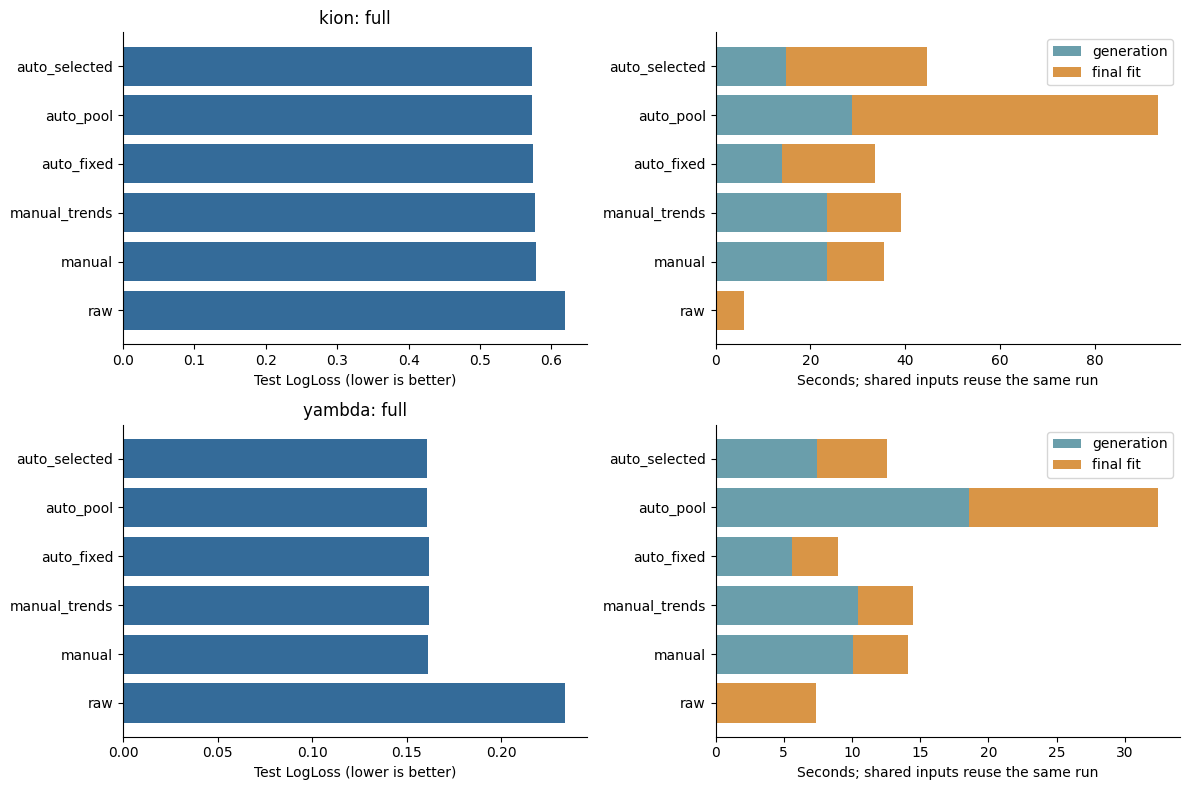

,dataset,shared_pool_generation_seconds,search_fit_seconds,models_fitted
0,kion,46.170186,290.673764,13
1,yambda,16.257849,98.792647,13


In [18]:
comparison = pd.concat([study["table"] for study in studies.values()], ignore_index=True)
columns = ["dataset", "mode", "method", "inputs", "logloss", "auc", "average_precision",
           "delta_logloss_vs_raw", "generation_seconds", "fit_seconds", "matrix_mib", "shared_with"]
display(comparison[columns].round(6))
comparison.to_csv(RUN / "comparison.csv", index=False)
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(12, 4*len(DATASETS)), squeeze=False)
for row, dataset in enumerate(DATASETS):
    table = studies[dataset]["table"]
    axes[row, 0].barh(table.method, table.logloss, color="#346b99")
    axes[row, 0].set(title=dataset + ": " + MODE, xlabel="Test LogLoss (lower is better)")
    axes[row, 1].barh(table.method, table.generation_seconds, label="generation", color="#6a9eab")
    axes[row, 1].barh(table.method, table.fit_seconds, left=table.generation_seconds, label="final fit", color="#d99546")
    axes[row, 1].set(xlabel="Seconds; shared inputs reuse the same run")
    axes[row, 1].legend()
plt.tight_layout()
plt.savefig(RUN / "comparison.png", dpi=140)
plt.show()
display(pd.DataFrame([{ "dataset": name, **study["cost"]} for name, study in studies.items()]))

## 8. Анализ признаков

Gain ниже взят из train splits финальной модели `auto_pool`. Он показывает использование
признаков бустингом, но не причинный вклад и не test permutation importance. Коррелирующие
окна делят gain между собой. Curve top-K использует search, поэтому сама по себе
не является независимым доказательством качества на новых данных.

kion selected primary windows; trend long windows remain in CSV


window,14d,180d,1d,21d,30d,3d,60d,7d,90d,all
entity,,,,,,,,,,
author,2,2,3,2,2,3,2,4,1,2
category_id,1,0,1,0,2,0,0,1,0,0
global,0,2,2,2,1,3,1,2,2,0
item_id,2,4,6,3,5,3,2,3,2,2
item_id/gender,2,2,4,2,2,3,2,2,1,0
user_id,4,4,0,1,2,1,3,3,3,5
user_id/author,0,0,0,0,0,0,0,0,0,2
user_id/category_id,0,2,0,0,0,0,1,0,1,1


Pruning reasons:


,removed
reason,
constant_or_near_constant,54
correlated_with,2
exact_duplicate_of,57
missing_or_sparse,15


yambda selected primary windows; trend long windows remain in CSV


window,14d,180d,1d,21d,30d,3d,60d,7d,90d,all
entity,,,,,,,,,,
author,0,1,0,0,1,0,0,0,0,1
category_id,0,0,0,0,1,0,0,0,0,0
global,2,0,0,0,0,0,0,2,0,1
user_id,4,2,3,2,4,2,2,3,3,7
user_id/author,1,1,1,1,1,0,2,0,1,3
user_id/item_id,0,2,0,1,1,1,1,0,1,5


Pruning reasons:


,removed
reason,
correlated_with,6


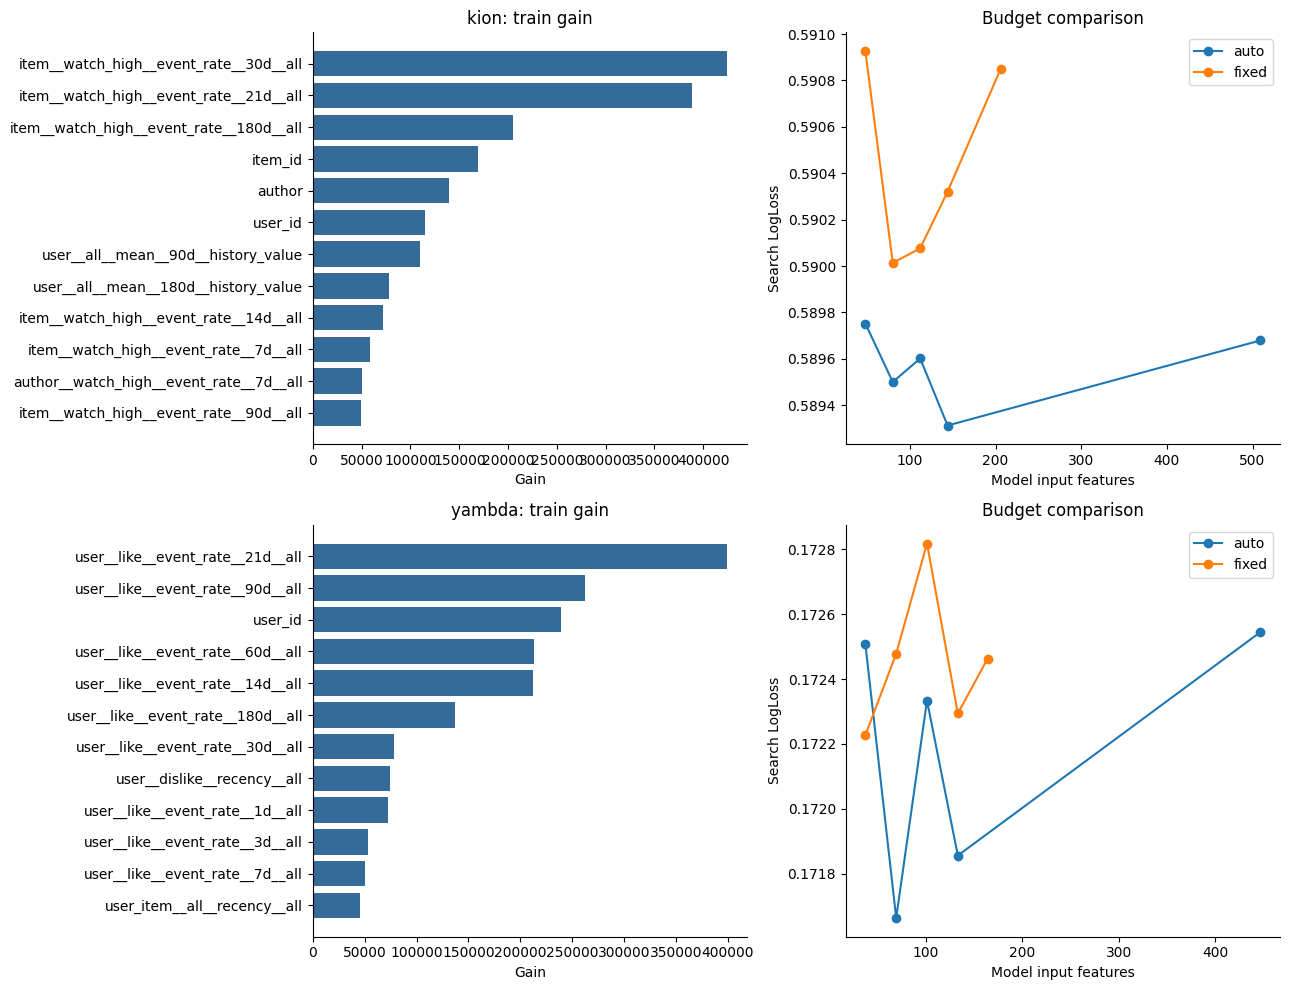

In [19]:
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(13, 5*len(DATASETS)), squeeze=False)
for i, dataset in enumerate(DATASETS):
    study = studies[dataset]
    top = study["importance"].head(12).iloc[::-1]
    axes[i, 0].barh(top.feature, top.gain, color="#346b99")
    axes[i, 0].set(title=dataset+": train gain", xlabel="Gain")
    for prefix in ["auto_", "fixed_"]:
        curve = study["search"][study["search"].method.str.startswith(prefix)].sort_values("inputs")
        axes[i, 1].plot(curve.inputs, curve.logloss, "o-", label=prefix.rstrip("_"))
    axes[i, 1].set(xlabel="Model input features", ylabel="Search LogLoss", title="Budget comparison")
    axes[i, 1].legend()
    selected = pd.DataFrame(study["selected_specs"])
    selected["entity"] = selected["keys"].map(lambda keys: "/".join(keys) or "global")
    selected["window"] = selected["window_days"].map(lambda value: "all" if pd.isna(value) else str(int(value))+"d")
    print(dataset, "selected primary windows; trend long windows remain in CSV")
    display(pd.crosstab(selected.entity, selected.window))
    print("Pruning reasons:")
    display(study["pruning"].assign(reason=study["pruning"].reason.str.split(":").str[0]).groupby("reason").size().to_frame("removed"))
plt.tight_layout()
plt.savefig(RUN / "feature_analysis.png", dpi=140)
plt.show()

## 9. Обсуждение

У manual/trends одинаковые параметры и training population; разница условно показывает
пользу добавления trends. Auto fixed против manual также меняет relations и primitives,
а auto pool против fixed — и окна, и состав surviving features. Поэтому весь выигрыш
автоматического набора нельзя приписать только выбору длины окна.

Ниже печатаются фактический test winner и фиксированный contrast auto-selected против
manual+trends. Winner не используется для нового выбора. User-cluster bootstrap учитывает
зависимость событий одного человека, но условен на одном split и фиксированных моделях;
неопределенность всего поиска в него не входит.

### Наблюдения полного запуска от 25 октября 2026

Эти значения относятся к сохраненному **full**, а не к demo.

**KION.** Raw LogLoss 0.619689, manual 0.577836. Добавление trends дает 0.577493: небольшой условный выигрыш. Auto fixed дает 0.573697; широкий pool — 0.572512. Выбранный на search набор из 144 входов дает 0.572429. Это 128 historical specs плюс 16 base columns; число inputs сокращено на 71.7% относительно pool из 509 при близком test качестве. Historical generation + final fit для selected заняли 44.5 s против 93.3 s для pool на этой машине; search оплачивается дополнительно.

**Yambda.** Raw LogLoss 0.234020, manual 0.161425. Trends слегка ухудшили результат до 0.161747; их польза не универсальна. Auto fixed — 0.161770, полный pool — 0.160768, selected — 0.160820 при 69 входах вместо 447. Selected уступил pool всего на 0.000052 LogLoss, а historical generation + final fit заняли 12.5 s против 32.4 s. Набор выбирался на search, а не по этому test различию.

Если приоритет — качество этого фиксированного эксперимента, на KION лучший observed score у selected, на Yambda — у pool. По балансу качества и стоимости selected выглядит практичным компромиссом на обоих источниках. Это не универсальный production winner: один split/seed, известный holdout и availability assumptions остаются ограничениями. Человеку все еще нужно задать допустимую грамматику; validation выбирает конкретные колонки.


In [20]:
for dataset, study in studies.items():
    table = study["table"]
    best = table.sort_values(["logloss", "inputs"]).iloc[0]
    print(dataset, "observed test winner:", best["method"], "LogLoss:", round(best.logloss, 6))
    print("auto_selected minus manual_trends:", study["bootstrap"])
    display(study["audit"].round(6))


kion observed test winner: auto_selected LogLoss: 0.572429
auto_selected minus manual_trends: {'delta_logloss': -0.005064914047550239, 'ci95': [-0.00554330551392229, -0.0045560444406228815], 'repeats': 300, 'conditional_on_fixed_models': True}


,dataset,method,logloss,auc,average_precision
0,kion,raw,0.638703,0.666643,0.511843
1,kion,manual,0.604035,0.712152,0.573506
2,kion,manual_trends,0.603246,0.712648,0.573088
3,kion,auto_fixed,0.590241,0.713745,0.574062
4,kion,auto_pool,0.589445,0.714655,0.574710
5,kion,auto_selected,0.589551,0.714348,0.573367


yambda observed test winner: auto_pool LogLoss: 0.160768
auto_selected minus manual_trends: {'delta_logloss': -0.0009267101812885871, 'ci95': [-0.001637598913320804, -0.00030124254937394603], 'repeats': 300, 'conditional_on_fixed_models': True}


,dataset,method,logloss,auc,average_precision
0,yambda,raw,0.234879,0.812967,0.971998
1,yambda,manual,0.171229,0.921373,0.989533
2,yambda,manual_trends,0.172484,0.920437,0.989371
3,yambda,auto_fixed,0.171955,0.920205,0.989216
4,yambda,auto_pool,0.170859,0.920874,0.989404
5,yambda,auto_selected,0.171100,0.920377,0.989300


## 10. Вывод

На KION лучший test LogLoss получен у auto selected, на Yambda — у полного auto pool.
Отбор сократил число входов с 509 до 144 и с 447 до 69 соответственно при близком
качестве. По соотношению качества и стоимости компактный набор выглядит разумным
выбором для этих экспериментов. Поиск требует дополнительных обучений, поэтому
его стоимость нужно учитывать отдельно от финального fit.

Автоматизация переносит ручной выбор отдельных колонок на уровень грамматики:
человек задает допустимые связи, агрегации, окна и бюджет, а validation определяет
конкретный набор. Полностью убрать участие человека эта процедура не позволяет.

Ограничения: один global split и один seed; test уже наблюдался ранее, поэтому
это повторная оценка на известном holdout. Исторические availability timestamps
отсутствуют. KION не содержит повторных user-item пар, 180d там эквивалентно
all-history; Yambda использует только explicit reactions. Production latency,
full-catalog retrieval и универсальная оптимальность окон не проверялись.

Источники данных: [KION](https://github.com/irsafilo/KION_DATASET),
[Yambda](https://huggingface.co/datasets/yandex/yambda),
[описание Yambda](https://arxiv.org/abs/2505.22238).
Точные revisions, SHA256 и параметры модели указаны выше. Model files, predictions,
protocol lock, CSV и время расчета сохраняются в `.runs/` при новом запуске.


In [21]:
checks = []
for dataset, study in studies.items():
    folder = Path(study["folder"])
    recorded = json.loads((folder / "files_sha256.json").read_text())
    assert all(sha256(folder / name) == digest for name, digest in recorded.items())
    for path in folder.glob("predictions_*.parquet"):
        saved = pl.read_parquet(path)
        scores = classification_scores(saved["label"].to_numpy(), saved["prediction"].to_numpy())
        method = path.stem.removeprefix("predictions_")
        row = study["table"].set_index("method").loc[method]
        assert abs(scores["logloss"]-row.logloss) < 1e-12
        assert abs(scores["auc"]-row.auc) < 1e-12
    checks.append({"dataset": dataset, "mode": MODE, "status": "PASS", "rows": frames[dataset].height,
                   "selected_specs": len(study["selected_specs"]), "predictions_rescored": True})
(RUN / "verification.json").write_text(json.dumps(checks, indent=2))
display(pd.DataFrame(checks))


,dataset,mode,status,rows,selected_specs,predictions_rescored
0,kion,full,PASS,1594519,128,True
1,yambda,full,PASS,989232,64,True
